## v4. Boundary losses in the ADAPTIVE big run (tracks_adaptive_11098723)

Same analysis as `v3.Meso_boundaries_bigrun_losses` (plain RK4 run), for the run made with `Run_parcels_UVW_adaptive.ipynb`
(`v1.Run_parcels_UVW.sh`): kernels SampleTS + `AdvectionRK4_3D_substep` (RK4-3D with sub-stepping at solid boundaries) + CheckError.
Releases every 5 days 1993-1994, 10000 particles each, 185 days, 6-hourly output.

Per particle flags:
* **deleted**: becomes NaN before the end of the store's written time span.
* **left_domain**: the particle reaches `north_exit_lat` (29 N) at any time, or is deleted within `domain_edge_cells` of the grid edge: it left the study region and **none of its flags count** (neither as a loss nor in the refinement statistics: at the northern edge the cell search fails and the kernel keeps halving the step, which inflates nrefine/ndry).
* **below_bed**: z > W bottom (`depthw[min(mbathy,49)]`) of the T cell **parcels uses** (corners f(j-1,i-1)..f(j,i))
* **frozen_exact**: lon and lat *identical* for >= `frozen_min_steps` consecutive 6-hourly outputs (really stuck)
* **frozen** (tolerance): |dlon|, |dlat| <= `frozen_tol` for >= `frozen_min_steps` outputs (includes very slow particles near the bed that move on later)
* **on_land**: mbathy == 0 at its cell; **above_surface**: z < 0
* **nrefine / ndry**: sub-steps redone with a smaller step / sub-steps taken while already in a zero-velocity cell (from the kernel)

Location category at each event: coast (cell or a 4-neighbour is land) / shelf_bottom (W bottom <= `shelf_max_depth`, particle in the deepest wet level or below) / ocean_bottom (W bottom > `shelf_max_depth`, same) / other.

In [1]:
# Parameters
tracks_dir = 'tracks_adaptive_11098723'
max_stores = None            # e.g. 2 for a test, None for all
out_put_step_hours = 6
run_time_days = 185          # obs beyond run_time_days*24/out_put_step_hours are ignored
frozen_min_steps = 8         # consecutive unchanged 6-hourly steps (8 = 2 days)
frozen_tol = 1e-7            # deg, tolerance on |dlon| and |dlat|
shelf_max_depth = 200.0      # m, W bottom <= this -> shelf, else ocean
domain_edge_cells = 3        # deletion within this many cells of the grid edge -> out of the domain
count_domain_edge_as_lost = False   # particles leaving the domain (e.g. at 30N) are far from the study region: not a loss
out_table = 'tracks_adaptive_11098723_boundary_losses.parquet'
north_exit_lat = 29.0         # particles reaching this latitude left the study region: ignored in the losses and refinement stats
plain_table = 'tracks_11098723_boundary_losses.parquet'   # v3 result for the plain RK4 run, for comparison

Hgr = "/work/bk1450/b383184/Amazon/Mercator/data/Hgr_cmesh.nc"
Zgr = "/work/bk1450/b383184/Amazon/Mercator/data/Zgr_cmesh2.nc"


In [2]:
import glob, gc, time as _time
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

_h = xr.open_dataset(Hgr); _z = xr.open_dataset(Zgr)
glamf = _h.glamf.isel(t=0).values
gphif = _h.gphif.isel(t=0).values
mbathy = _z.mbathy.isel(t=0).values.astype(int)
depthw = _z.gdepw_0.isel(t=0).values
nz = len(depthw)
w_bottom = np.where(mbathy > 0, depthw[np.minimum(mbathy, nz - 1)], 0.0)
# top of the deepest wet T level (W level above the W bottom)
deep_top = np.where(mbathy > 0, depthw[np.clip(mbathy - 1, 0, nz - 1)], 0.0)

land = mbathy == 0
coast_cell = land.copy()
coast_cell[1:, :] |= land[:-1, :]; coast_cell[:-1, :] |= land[1:, :]
coast_cell[:, 1:] |= land[:, :-1]; coast_cell[:, :-1] |= land[:, 1:]

def tcell(lon, lat):
    """T cell (j,i) parcels uses: corners f(j-1,i-1)..f(j,i)"""
    i = np.searchsorted(glamf[250, :], lon)
    j = np.searchsorted(gphif[:, 600], lat)
    for _ in range(2):   # refine on the (nearly regular) curvilinear grid
        i = np.clip(i, 1, glamf.shape[1] - 1); j = np.clip(j, 1, glamf.shape[0] - 1)
        i = i + (lon > glamf[j, i]).astype(int) - (lon <= glamf[j, i - 1]).astype(int)
        j = j + (lat > gphif[j, i]).astype(int) - (lat <= gphif[j - 1, i]).astype(int)
    i = np.clip(i, 1, glamf.shape[1] - 1); j = np.clip(j, 1, glamf.shape[0] - 1)
    return j, i

cats = np.array(['coast', 'shelf_bottom', 'ocean_bottom', 'other'])
def category(j, i, z):
    """0 coast, 1 shelf_bottom, 2 ocean_bottom, 3 other"""
    deep = z >= deep_top[j, i]
    c = np.full(np.shape(j), 3)
    c[deep & (w_bottom[j, i] > shelf_max_depth)] = 2
    c[deep & (w_bottom[j, i] <= shelf_max_depth)] = 1
    c[coast_cell[j, i]] = 0
    return c

stores = sorted(glob.glob(f'{tracks_dir}/Parcels_run_*.zarr'))
if max_stores is not None:
    stores = stores[:max_stores]
print(len(stores), 'stores')

144 stores


## Coverage of each store

In [3]:
nmax = int(run_time_days * 24 / out_put_step_hours)
cov = []
for f in stores:
    ds = xr.open_zarr(f)
    tt = ds.time.values
    written = (~np.isnat(tt)).any(axis=0)
    t0 = tt[:, 0]
    cov.append(dict(release=pd.Timestamp(f.split('_')[-1][:10]), n_traj=ds.sizes['trajectory'], n_obs=ds.sizes['obs'],
                    written_obs=int(written.sum()), last_written_obs=int(np.where(written)[0][-1]),
                    first_time=pd.Timestamp(np.nanmin(t0)), last_time=pd.Timestamp(np.nanmax(tt)),
                    n_alive_obs0=int((~np.isnat(t0)).sum())))
    ds.close(); del tt
coverage = pd.DataFrame(cov).set_index('release')
coverage['complete'] = (coverage.last_written_obs >= nmax - 1) & (coverage.first_time == coverage.index)
coverage

,n_traj,n_obs,written_obs,last_written_obs,first_time,last_time,n_alive_obs0,complete
release,,,,,,,,
1993-01-06,10000,740,740,739,1993-01-06,1993-07-09 18:00:00,10000,True
1993-01-11,10000,740,740,739,1993-01-11,1993-07-14 18:00:00,10000,True
1993-01-16,10000,925,741,740,1993-01-16,1993-07-19 20:20:00,10000,True
1993-01-21,10000,740,740,739,1993-01-21,1993-07-24 18:00:00,10000,True
1993-01-26,10000,740,740,739,1993-01-26,1993-07-29 18:00:00,10000,True
...,...,...,...,...,...,...,...,...
1994-12-07,10000,740,740,739,1994-12-07,1995-06-09 18:00:00,10000,True
1994-12-12,10000,740,740,739,1994-12-12,1995-06-14 18:00:00,10000,True
1994-12-17,10000,740,740,739,1994-12-17,1995-06-19 18:00:00,10000,True


## Cell mapping spot check (tcell vs point-in-quad on a sample)

In [4]:
from matplotlib.path import Path as _P
ds = xr.open_zarr(stores[0])
rng = np.random.default_rng(0)
_lon = ds.lon.values.ravel(); _lat = ds.lat.values.ravel(); ds.close()
ok = ~np.isnan(_lon)
k = rng.choice(np.where(ok)[0], 3000, replace=False)
jj, ii = tcell(_lon[k], _lat[k])
inside = np.array([_P([(glamf[j-1, i-1], gphif[j-1, i-1]), (glamf[j-1, i], gphif[j-1, i]),
                       (glamf[j, i], gphif[j, i]), (glamf[j, i-1], gphif[j, i-1])]).contains_point((x, y))
                   for j, i, x, y in zip(jj, ii, _lon[k], _lat[k])])
print(f'tcell agrees with point-in-quad for {inside.sum()}/{len(k)} sampled positions')
del _lon, _lat; _ = gc.collect()

tcell agrees with point-in-quad for 3000/3000 sampled positions


## Per-particle classification, one store at a time

In [5]:
def first_true(m):
    """index of first True along axis 1, -1 if none"""
    a = m.any(axis=1)
    return np.where(a, np.argmax(m, axis=1), -1)

rows = []
cum_lost = {}       # release -> fraction lost by obs
tic = _time.time()
for f in stores:
    rel = pd.Timestamp(f.split('_')[-1][:10])
    ds = xr.open_zarr(f)
    n_obs = min(ds.sizes['obs'], nmax)
    lon = ds.lon.values[:, :n_obs]; lat = ds.lat.values[:, :n_obs]; z = ds.z.values[:, :n_obs]
    written = (~np.isnat(ds.time.values[:, :n_obs])).any(axis=0)
    nref = np.nan_to_num(ds.nrefine.values[:, :n_obs]).max(axis=1) if 'nrefine' in ds else np.zeros(lon.shape[0])
    ndry = np.nan_to_num(ds.ndry.values[:, :n_obs]).max(axis=1) if 'ndry' in ds else np.zeros(lon.shape[0])
    ds.close()
    last_w = int(np.where(written)[0][-1])          # last obs actually written for this store
    N = lon.shape[0]
    valid = ~np.isnan(lat)

    J, I = tcell(np.nan_to_num(lon), np.nan_to_num(lat))
    wb = w_bottom[J, I]
    below = valid & (z > wb)
    onland = valid & (mbathy[J, I] == 0)
    above = valid & (z < 0)

    # deleted: valid at t-1, NaN at t, with t <= last written obs
    lastvalid = np.where(valid.any(axis=1), valid.shape[1] - 1 - np.argmax(valid[:, ::-1], axis=1), -1)
    deleted = (lastvalid >= 0) & (lastvalid < last_w)
    del_obs = np.where(deleted, lastvalid + 1, -1)

    # frozen: run of consecutive steps with unchanged lon and lat
    still = (np.abs(np.diff(lon, axis=1)) <= frozen_tol) & (np.abs(np.diff(lat, axis=1)) <= frozen_tol)
    run = np.zeros(N, int); maxrun = np.zeros(N, int); maxstart = np.full(N, -1)
    firststart = np.full(N, -1)
    for t in range(still.shape[1]):
        run = np.where(still[:, t], run + 1, 0)
        better = run > maxrun
        maxrun = np.where(better, run, maxrun)
        maxstart = np.where(better, t + 1 - run, maxstart)      # obs where the frozen position starts
        newf = (run == frozen_min_steps) & (firststart < 0)
        firststart = np.where(newf, t + 1 - run, firststart)
    frozen = maxrun >= frozen_min_steps
    frozen_exact = frozen  # placeholder, exact-equality count computed below
    still_exact = (np.diff(lon, axis=1) == 0) & (np.diff(lat, axis=1) == 0)
    run = np.zeros(N, int); mx = np.zeros(N, int)
    for t in range(still_exact.shape[1]):
        run = np.where(still_exact[:, t], run + 1, 0); mx = np.maximum(mx, run)
    frozen_exact = mx >= frozen_min_steps

    b_obs = first_true(below); l_obs = first_true(onland); a_obs = first_true(above)
    p = np.arange(N)
    d = dict(release=np.full(N, rel), traj=p, deleted=deleted, below_bed=below.any(axis=1), frozen=frozen,
             frozen_exact=frozen_exact, on_land=onland.any(axis=1), above_surface=above.any(axis=1),
             frozen_in_ground=frozen & below[p, np.maximum(firststart, 0)],
             frozen_max_days=maxrun * out_put_step_hours / 24,
             frozen_max_start_day=np.where(frozen, maxstart * out_put_step_hours / 24, np.nan),
             max_below_bed_m=np.where(below.any(axis=1), np.nanmax(np.where(below, z - wb, -np.inf), axis=1), np.nan),
             days_below_bed=below.sum(axis=1) * out_put_step_hours / 24,
             min_z=np.nanmin(z, axis=1))
    # event obs per flag: deletion -> last valid position; frozen -> start of first qualifying run
    ev = dict(deleted=np.where(deleted, lastvalid, -1), below_bed=b_obs, frozen=firststart,
              on_land=l_obs, above_surface=a_obs)
    for k_, o in ev.items():
        has = o >= 0; oo = np.maximum(o, 0)
        jj_, ii_, zz_ = J[p, oo], I[p, oo], z[p, oo]
        d[f'{k_}_day'] = np.where(has, (del_obs if k_ == 'deleted' else o) * out_put_step_hours / 24, np.nan)
        d[f'{k_}_cat'] = np.where(has, cats[category(jj_, ii_, np.nan_to_num(zz_))], '')
        if k_ in ('deleted', 'below_bed', 'frozen'):
            d[f'{k_}_lon'] = np.where(has, lon[p, oo], np.nan)
            d[f'{k_}_lat'] = np.where(has, lat[p, oo], np.nan)
            d[f'{k_}_z'] = np.where(has, zz_, np.nan)
            d[f'{k_}_wbottom'] = np.where(has, wb[p, oo], np.nan)
    jd, id_ = J[p, np.maximum(lastvalid, 0)], I[p, np.maximum(lastvalid, 0)]
    d['deleted_at_domain_edge'] = deleted & ((jd <= domain_edge_cells) | (jd >= glamf.shape[0] - 1 - domain_edge_cells) |
                                             (id_ <= domain_edge_cells) | (id_ >= glamf.shape[1] - 1 - domain_edge_cells) |
                                             (lat[p, np.maximum(lastvalid, 0)] >= north_exit_lat))
    d['nrefine'] = nref.astype(int); d['ndry'] = ndry.astype(int)
    d['below_bed_m_at_event'] = np.where(b_obs >= 0, d['below_bed_z'] - d['below_bed_wbottom'], np.nan)
    df = pd.DataFrame(d)

    # particles deleted at the domain edge left the domain (far from the study region): not a loss
    df['left_domain'] = (df.deleted & df.deleted_at_domain_edge) | (np.nanmax(lat, axis=1) >= north_exit_lat)

    # combined lost event: earliest of below_bed / frozen / deleted (inside the domain) / on_land
    lost_flags = ['below_bed', 'frozen', 'deleted', 'on_land']
    lost_mask = df[lost_flags].copy()
    if not count_domain_edge_as_lost:
        lost_mask['deleted'] = df.deleted & ~df.left_domain
    df['lost'] = lost_mask.any(axis=1) & ~df.left_domain
    days = df[[f'{k_}_day' for k_ in lost_flags]].to_numpy()
    if not count_domain_edge_as_lost:
        days[df.left_domain.to_numpy(), lost_flags.index('deleted')] = np.nan   # leaving the domain is not a loss event
    first = np.where(df.lost, np.nanargmin(np.where(np.isnan(days), np.inf, days), axis=1), -1)
    df['lost_day'] = np.where(df.lost, np.nanmin(np.where(np.isnan(days), np.inf, days), axis=1), np.nan)
    df['lost_by'] = np.where(df.lost, np.array(lost_flags)[np.maximum(first, 0)], '')
    catm = df[[f'{k_}_cat' for k_ in lost_flags]].to_numpy()
    df['lost_cat'] = np.where(df.lost, catm[p, np.maximum(first, 0)], '')
    for c_ in ('lon', 'lat', 'z'):
        src = df[[f'{k_}_{c_}' for k_ in ('below_bed', 'frozen', 'deleted')] ].to_numpy()
        # on_land events have no stored position: use first of the three that exists at lost_day
        df[f'lost_{c_}'] = np.nan
        for kk, k_ in enumerate(('below_bed', 'frozen', 'deleted')):
            sel = (df.lost_by == k_).to_numpy()
            df.loc[sel, f'lost_{c_}'] = src[sel, kk]
    df['n_obs_used'] = n_obs; df['last_written_day'] = last_w * out_put_step_hours / 24
    rows.append(df)

    obs_days = np.arange(n_obs) * out_put_step_hours / 24
    cum_lost[rel] = pd.Series([(df.lost_day.to_numpy() <= t).mean() * 100 for t in obs_days], index=obs_days)
    print(f"{rel.date()}  lost {df.lost.mean()*100:5.2f}%  below {df.below_bed.mean()*100:5.2f}%  "
          f"frozen {df.frozen.mean()*100:5.2f}%  deleted {df.deleted.mean()*100:5.2f}%  "
          f"(left domain {df.left_domain.mean()*100:5.2f}%)  ({_time.time()-tic:.0f}s)")
    del lon, lat, z, valid, J, I, wb, below, onland, above, still, still_exact, df
    _ = gc.collect()

res = pd.concat(rows, ignore_index=True); del rows
try:
    res.to_parquet(out_table); print('saved', out_table)
except Exception as e:
    out_table = out_table.replace('.parquet', '.csv'); res.to_csv(out_table, index=False); print('saved', out_table, e)
print(len(res), 'particles')

1993-01-06  lost  0.05%  below  0.00%  frozen  0.05%  deleted  0.56%  (left domain  0.56%)  (2s)


1993-01-11  lost  0.01%  below  0.00%  frozen  0.01%  deleted  0.51%  (left domain  0.52%)  (4s)


1993-01-16  lost  0.05%  below  0.00%  frozen  0.05%  deleted  0.46%  (left domain  0.49%)  (7s)


1993-01-21  lost  0.10%  below  0.00%  frozen  0.10%  deleted  0.22%  (left domain  0.25%)  (9s)


1993-01-26  lost  0.07%  below  0.00%  frozen  0.07%  deleted  0.00%  (left domain  0.01%)  (11s)


1993-01-31  lost  0.10%  below  0.00%  frozen  0.10%  deleted  0.00%  (left domain  0.00%)  (14s)


... (135 outputs left out)

1994-12-17  lost  0.14%  below  0.00%  frozen  0.14%  deleted  0.07%  (left domain  0.08%)  (356s)


1994-12-22  lost  0.08%  below  0.00%  frozen  0.08%  deleted  0.01%  (left domain  0.01%)  (358s)


1994-12-27  lost  0.06%  below  0.00%  frozen  0.06%  deleted  0.07%  (left domain  0.07%)  (361s)


saved tracks_adaptive_11098723_boundary_losses.parquet
1440000 particles


## a) % of particles per flag and location category

In [6]:
flags = ['deleted', 'left_domain', 'below_bed', 'frozen', 'on_land', 'above_surface', 'lost']
N = len(res)
tab = {}
for fl in flags:
    catcol = 'lost_cat' if fl == 'lost' else ('deleted_cat' if fl == 'left_domain' else f'{fl}_cat')
    r = {'total': res[fl].mean() * 100}
    for c in cats:
        r[c] = ((res[catcol] == c) & res[fl]).sum() / N * 100
    tab[fl] = r
overall = pd.DataFrame(tab).T[['total', *cats]]
print(f'% of all {N} particles (category = location at the event of that flag)')
overall.round(3)

% of all 1440000 particles (category = location at the event of that flag)


,total,coast,shelf_bottom,ocean_bottom,other
deleted,0.187,0.000,0.000,0.0,0.187
left_domain,0.222,0.000,0.000,0.0,0.187
below_bed,0.000,0.000,0.000,0.0,0.000
frozen,0.088,0.042,0.042,0.0,0.004
on_land,0.000,0.000,0.000,0.0,0.000
above_surface,0.000,0.000,0.000,0.0,0.000
lost,0.088,0.042,0.042,0.0,0.004


In [7]:
fz = res[res.frozen]
print(f"frozen: {len(fz)} particles ({len(fz)/N*100:.3f}%)")
print(f"  also below_bed (ever)          : {fz.below_bed.sum()} ({fz.below_bed.mean()*100:.1f}% of frozen, {fz.below_bed.sum()/N*100:.3f}% of all)")
print(f"  in the ground when frozen      : {fz.frozen_in_ground.sum()} ({fz.frozen_in_ground.mean()*100:.1f}% of frozen)")
print(f"  in water when frozen           : {(~fz.frozen_in_ground).sum()} ({(~fz.frozen_in_ground).mean()*100:.1f}% of frozen, {(~fz.frozen_in_ground).sum()/N*100:.3f}% of all)")
print(f"  frozen with exact equality     : {res.frozen_exact.sum()} (tolerance {frozen_tol} deg: {res.frozen.sum()})")
print(f"  frozen in water, durations [days]: {sorted(fz[~fz.frozen_in_ground].frozen_max_days.round(2).tolist())[:50]}")
print(f"  frozen in water, W bottom - z at freeze [m]: {sorted((fz[~fz.frozen_in_ground].frozen_wbottom - fz[~fz.frozen_in_ground].frozen_z).round(2).tolist())[:50]}")
print(f"  longest frozen duration [days] : median {fz.frozen_max_days.median():.1f}, max {fz.frozen_max_days.max():.1f}")
print(f"  frozen category, in ground vs in water:")
print(pd.crosstab(fz.frozen_cat, fz.frozen_in_ground.map({True: 'in_ground', False: 'in_water'}), margins=True))

frozen: 1270 particles (0.088%)
  also below_bed (ever)          : 1 (0.1% of frozen, 0.000% of all)
  in the ground when frozen      : 1 (0.1% of frozen)
  in water when frozen           : 1269 (99.9% of frozen, 0.088% of all)
  frozen with exact equality     : 80 (tolerance 1e-07 deg: 1270)
  frozen in water, durations [days]: [2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0]
  frozen in water, W bottom - z at freeze [m]: [0.0, 0.0, 0.01, 0.01, 0.01, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.04, 0.04, 0.04, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.06, 0.06, 0.06, 0.06, 0.06, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.08, 0.08]
  longest frozen duration [days] : median 4.5, max 178.2
  frozen catego

In [8]:
per_release = res.groupby('release')[flags].mean() * 100
for c in ['coast', 'shelf_bottom', 'ocean_bottom', 'other']:
    per_release[f'lost_{c}'] = res.assign(x=(res.lost_cat == c)).groupby('release').x.mean() * 100
per_release.round(2)

,deleted,left_domain,below_bed,frozen,on_land,above_surface,lost,lost_coast,lost_shelf_bottom,lost_ocean_bottom,lost_other
release,,,,,,,,,,,
1993-01-06,0.56,0.56,0.0,0.05,0.0,0.0,0.05,0.02,0.03,0.0,0.00
1993-01-11,0.51,0.52,0.0,0.01,0.0,0.0,0.01,0.01,0.00,0.0,0.00
1993-01-16,0.46,0.49,0.0,0.05,0.0,0.0,0.05,0.03,0.02,0.0,0.00
1993-01-21,0.22,0.25,0.0,0.10,0.0,0.0,0.10,0.09,0.01,0.0,0.00
1993-01-26,0.00,0.01,0.0,0.07,0.0,0.0,0.07,0.05,0.02,0.0,0.00
...,...,...,...,...,...,...,...,...,...,...,...
1994-12-07,0.10,0.12,0.0,0.17,0.0,0.0,0.17,0.08,0.08,0.0,0.01
1994-12-12,0.21,0.22,0.0,0.10,0.0,0.0,0.10,0.05,0.04,0.0,0.01
1994-12-17,0.07,0.08,0.0,0.14,0.0,0.0,0.14,0.06,0.08,0.0,0.00


## b) Combined lost fraction and overlap between flags

In [9]:
lf = ['below_bed', 'frozen', 'deleted', 'on_land']
print(f"lost (below_bed | frozen | deleted inside the domain | on_land): {res.lost.sum()} = {res.lost.mean()*100:.3f}%"
      f"  (left the domain, not counted: {res.left_domain.sum()} = {res.left_domain.mean()*100:.3f}%)")
lost_parts = res[lf].assign(deleted=res.deleted & (count_domain_edge_as_lost | ~res.left_domain))
combo = lost_parts[res.lost].apply(lambda r: ' + '.join([k for k in lf if r[k]]), axis=1)
overlap = combo.value_counts().to_frame('n'); overlap['% of all'] = overlap.n / N * 100; overlap['% of lost'] = overlap.n / res.lost.sum() * 100
display(overlap.round(3))
dd = res[res.deleted]
print(f"deleted: {len(dd)} ({len(dd)/N*100:.3f}%), of which at the domain edge (<= {domain_edge_cells} cells): {dd.deleted_at_domain_edge.sum()}; "
      f"lat range {dd.deleted_lat.min():.2f}..{dd.deleted_lat.max():.2f}, lon range {dd.deleted_lon.min():.2f}..{dd.deleted_lon.max():.2f}, "
      f"deletion day range {dd.deleted_day.min()}..{dd.deleted_day.max()}")
pair = pd.DataFrame({a: {b: (res[a] & res[b]).mean() * 100 for b in lf + ['above_surface']} for a in lf + ['above_surface']})
print('pairwise overlap, % of all particles (diagonal = flag total)')
display(pair.round(3))
print('lost by the first event:')
display((pd.crosstab(res[res.lost].lost_by, res[res.lost].lost_cat, margins=True) / N * 100).round(3))

lost (below_bed | frozen | deleted inside the domain | on_land): 1270 = 0.088%  (left the domain, not counted: 3196 = 0.222%)


,n,% of all,% of lost
frozen,1269,0.088,99.921
below_bed + frozen,1,0.000,0.079


deleted: 2699 (0.187%), of which at the domain edge (<= 3 cells): 2699; lat range 29.95..30.02, lon range -87.04..-61.25, deletion day range 133.5..184.75
pairwise overlap, % of all particles (diagonal = flag total)


,below_bed,frozen,deleted,on_land,above_surface
below_bed,0.0,0.000,0.000,0.0,0.0
frozen,0.0,0.088,0.000,0.0,0.0
deleted,0.0,0.000,0.187,0.0,0.0
on_land,0.0,0.000,0.000,0.0,0.0
above_surface,0.0,0.000,0.000,0.0,0.0


lost by the first event:


lost_cat,coast,other,shelf_bottom,All
lost_by,,,,
below_bed,0.000,0.000,0.000,0.000
frozen,0.042,0.004,0.041,0.088
All,0.042,0.004,0.042,0.088


## c) Cumulative % lost vs days since release

In [10]:
cum = pd.DataFrame(cum_lost)
cum_mean = cum.mean(axis=1)
cum_tab = pd.DataFrame({'mean': cum_mean, 'min': cum.min(axis=1), 'max': cum.max(axis=1)})
cum_tab.loc[[d for d in [1, 5, 10, 20, 30, 60, 90, 120, 150, 184.75] if d in cum_tab.index]].round(3)

,mean,min,max
1.00,0.000,0.0,0.00
5.00,0.000,0.0,0.00
10.00,0.000,0.0,0.01
20.00,0.002,0.0,0.04
30.00,0.008,0.0,0.07
60.00,0.047,0.0,0.20
90.00,0.072,0.0,0.34
120.00,0.080,0.0,0.35
150.00,0.084,0.0,0.35
184.75,0.088,0.0,0.40


## Plots

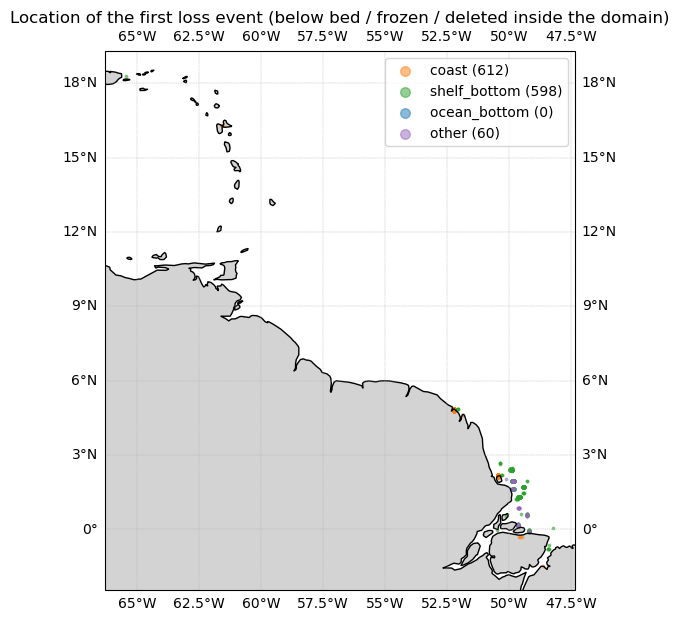

In [11]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
colors = {'coast': 'tab:orange', 'shelf_bottom': 'tab:green', 'ocean_bottom': 'tab:blue', 'other': 'tab:purple'}
L = res[res.lost & res.lost_lon.notna()]
fig = plt.figure(figsize=(11, 7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='lightgray'); ax.coastlines(resolution='50m')
ax.gridlines(draw_labels=True, linestyle='--', linewidth=0.3)
for c, col in colors.items():
    s = L[L.lost_cat == c]
    ax.scatter(s.lost_lon, s.lost_lat, s=3, color=col, alpha=0.5, transform=ccrs.PlateCarree(), label=f'{c} ({len(s)})')
ax.legend(loc='upper right', markerscale=4)
plt.title('Location of the first loss event (below bed / frozen / deleted inside the domain)')
plt.show()

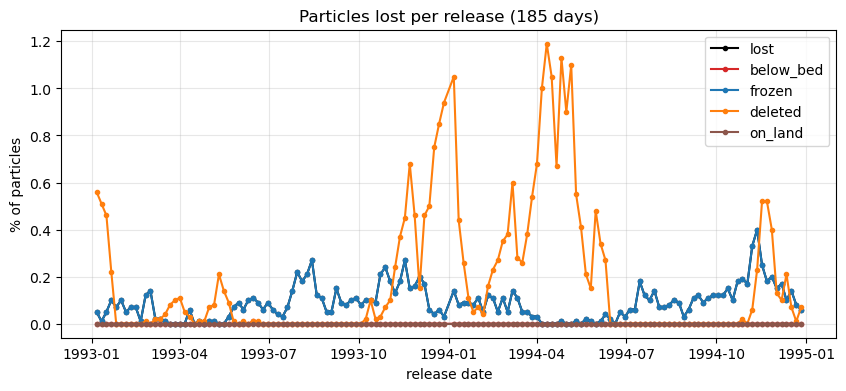

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
for fl, col in [('lost', 'k'), ('below_bed', 'tab:red'), ('frozen', 'tab:blue'), ('deleted', 'tab:orange'), ('on_land', 'tab:brown')]:
    ax.plot(per_release.index, per_release[fl], 'o-', ms=3, color=col, label=fl)
ax.set_ylabel('% of particles'); ax.set_xlabel('release date'); ax.legend(); ax.grid(alpha=0.3)
plt.title('Particles lost per release (185 days)'); plt.show()

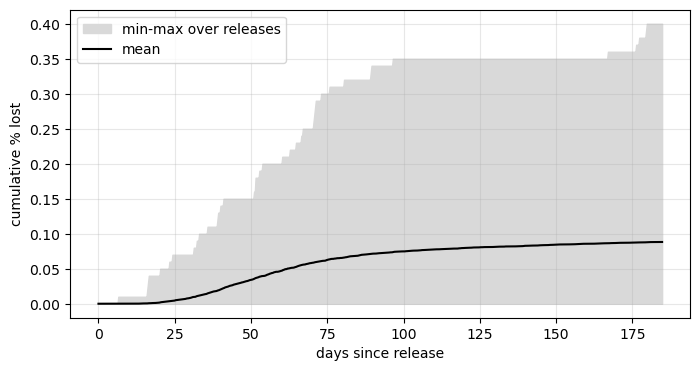

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(cum.index, cum.min(axis=1), cum.max(axis=1), color='0.85', label='min-max over releases')
ax.plot(cum.index, cum_mean, 'k', label='mean')
ax.set_xlabel('days since release'); ax.set_ylabel('cumulative % lost'); ax.legend(); ax.grid(alpha=0.3)
plt.show()

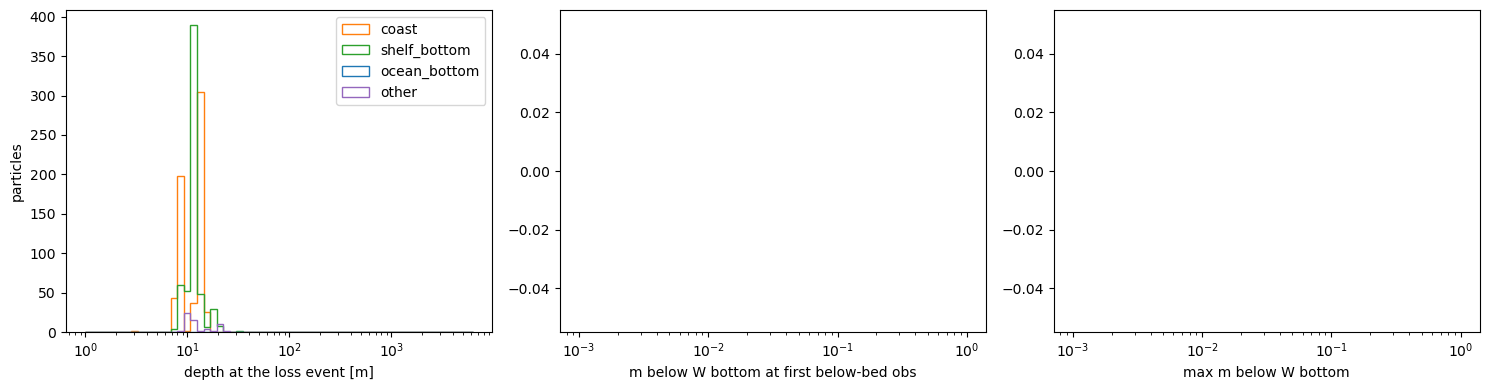

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for c, col in colors.items():
    s = res[res.lost_cat == c]
    axes[0].hist(s.lost_z.dropna(), bins=np.logspace(0, 3.8, 60), histtype='step', color=col, label=c)
axes[0].set_xscale('log'); axes[0].set_xlabel('depth at the loss event [m]'); axes[0].set_ylabel('particles'); axes[0].legend()
b = res.below_bed_m_at_event.dropna()
axes[1].hist(b, bins=np.logspace(-3, np.log10(max(b.max(), 1)), 60) if len(b) else 10, color='tab:red')
axes[1].set_xscale('log'); axes[1].set_xlabel('m below W bottom at first below-bed obs')
m = res.max_below_bed_m.dropna()
axes[2].hist(m, bins=np.logspace(-3, np.log10(max(m.max(), 1)), 60) if len(m) else 10, color='tab:red')
axes[2].set_xscale('log'); axes[2].set_xlabel('max m below W bottom')
plt.tight_layout(); plt.show()

In [15]:
# numbers for the conclusions
print(overall.round(3).to_string())
print(f'per-release lost %: min {per_release.lost.min():.2f}  max {per_release.lost.max():.2f}  mean {per_release.lost.mean():.2f}')
if len(per_release) > 1:
    print(f'corr(lost %, release index) = {np.corrcoef(np.arange(len(per_release)), per_release.lost)[0, 1]:.2f}')
print(cum_tab.loc[[d for d in [1, 10, 30, 90, 184.75] if d in cum_tab.index]].round(3).to_string())

               total  coast  shelf_bottom  ocean_bottom  other
deleted        0.187  0.000         0.000           0.0  0.187
left_domain    0.222  0.000         0.000           0.0  0.187
below_bed      0.000  0.000         0.000           0.0  0.000
frozen         0.088  0.042         0.042           0.0  0.004
on_land        0.000  0.000         0.000           0.0  0.000
above_surface  0.000  0.000         0.000           0.0  0.000
lost           0.088  0.042         0.042           0.0  0.004
per-release lost %: min 0.00  max 0.40  mean 0.09
corr(lost %, release index) = 0.28
         mean  min   max
1.00    0.000  0.0  0.00
10.00   0.000  0.0  0.01
30.00   0.008  0.0  0.07
90.00   0.072  0.0  0.34
184.75  0.088  0.0  0.40


## d) Adaptive stepping: refinements and comparison with the plain RK4 run

In [16]:
inside = res[~res.left_domain]      # particles that stayed in the study region (refinement stats of the others are edge artefacts)
print(f"particles that stayed in the study region: {len(inside)}")
print(f"  with at least one refined sub-step: {(inside.nrefine > 0).sum()} ({(inside.nrefine > 0).mean()*100:.2f}%), "
      f"total refined sub-steps {inside.nrefine.sum()}, median/max per refined particle "
      f"{inside.nrefine[inside.nrefine > 0].median():.0f}/{inside.nrefine.max()}")
print(f"  with ndry > 0 (step taken while already in a zero-velocity cell): {(inside.ndry > 0).sum()} ({(inside.ndry > 0).mean()*100:.3f}%)")
lft = res[res.left_domain]
print(f"particles that left (excluded): {len(lft)}; their refined sub-steps {lft.nrefine.sum()} (max {lft.nrefine.max() if len(lft) else 0}), ndry>0: {(lft.ndry > 0).sum()}")
print(f"left the study region (north exit / domain edge): {res.left_domain.sum()} ({res.left_domain.mean()*100:.3f}%) -> not counted as lost")
real = (res.below_bed | res.frozen_exact | res.on_land | res.deleted) & ~res.left_domain
print(f"REAL losses (below_bed | frozen_exact | on_land | deleted inside the domain): {real.sum()} = {real.mean()*100:.4f}% of {len(res)}")
slow = res.frozen & ~res.frozen_exact & ~res.left_domain
print(f"slow near the bed (frozen only with the {frozen_tol} deg tolerance, not identical positions): {slow.sum()} = {slow.mean()*100:.4f}%")
print('by category (% of all particles):')
cat_of = res.below_bed_cat.where(res.below_bed, res.frozen_cat.where(res.frozen_exact, res.deleted_cat))
display((pd.crosstab(cat_of[real], 'real losses') / len(res) * 100).round(4))
print('\nstuck particles, details:')
display(res[real][['release', 'traj', 'below_bed', 'frozen_exact', 'on_land', 'deleted', 'frozen_max_days', 'frozen_cat',
                   'max_below_bed_m', 'below_bed_cat', 'nrefine', 'ndry', 'frozen_lon', 'frozen_lat', 'frozen_z', 'frozen_wbottom']].head(50))

particles that stayed in the study region: 1436804
  with at least one refined sub-step: 82134 (5.72%), total refined sub-steps 176459, median/max per refined particle 1/25
  with ndry > 0 (step taken while already in a zero-velocity cell): 76 (0.005%)
particles that left (excluded): 3196; their refined sub-steps 1019649 (max 2062), ndry>0: 494
left the study region (north exit / domain edge): 3196 (0.222%) -> not counted as lost
REAL losses (below_bed | frozen_exact | on_land | deleted inside the domain): 80 = 0.0056% of 1440000
slow near the bed (frozen only with the 1e-07 deg tolerance, not identical positions): 1190 = 0.0826%
by category (% of all particles):


col_0,real losses
below_bed_cat,
coast,0.0041
other,0.0001
shelf_bottom,0.0014



stuck particles, details:


,release,traj,below_bed,frozen_exact,on_land,deleted,frozen_max_days,frozen_cat,max_below_bed_m,below_bed_cat,nrefine,ndry,frozen_lon,frozen_lat,frozen_z,frozen_wbottom
35412,1993-01-21,5412,False,True,False,False,121.75,coast,NaN,,1,8772,-52.208332,4.794774,8.589048,8.729996
39885,1993-01-21,9885,False,True,False,False,125.50,coast,NaN,,1,9055,-52.208332,4.816938,8.556424,8.729996
46660,1993-01-26,6660,False,True,False,False,126.00,coast,NaN,,1,9085,-52.208332,4.841155,8.575556,8.729996
52427,1993-01-31,2427,False,True,False,False,67.75,coast,NaN,,2,4891,-52.208332,4.868343,8.572645,8.729996
73900,1993-02-10,3900,False,True,False,False,119.75,coast,NaN,,2,8629,-52.208332,4.825708,8.574339,8.729996
83966,1993-02-15,3966,False,True,False,False,106.50,coast,NaN,,1,7671,-52.208332,4.802525,8.511411,8.729996
101511,1993-02-25,1511,False,True,False,False,96.25,coast,NaN,,1,6932,-52.208332,4.803260,8.560515,8.729996
110140,1993-03-02,140,False,True,False,False,130.75,coast,NaN,,1,9419,-52.208332,4.795881,8.539634,8.729996
110784,1993-03-02,784,False,True,False,False,121.50,coast,NaN,,1,8760,-52.208332,4.845887,8.554474,8.729996
114862,1993-03-02,4862,False,True,False,False,123.25,coast,NaN,,2,8890,-52.208332,4.836941,8.659966,8.729996


In [17]:
# plain RK4 (v3) vs adaptive on the releases both runs have
import os
if os.path.exists(plain_table):
    pl = pd.read_parquet(plain_table)
    common = sorted(set(pl.release) & set(res.release))
    a = res[res.release.isin(common)]; b = pl[pl.release.isin(common)]
    def rates(x):
        left = ((x.deleted & x.deleted_at_domain_edge) | x.left_domain) if 'left_domain' in x else (x.deleted & x.deleted_at_domain_edge)
        return pd.Series({'particles': len(x),
                          'below_bed %': x.below_bed.mean()*100,
                          'frozen_exact %': x.frozen_exact.mean()*100,
                          'frozen (tolerance) %': x.frozen.mean()*100,
                          'on_land %': x.on_land.mean()*100,
                          'deleted inside domain %': (x.deleted & ~left).mean()*100,
                          'left domain %': left.mean()*100,
                          'REAL lost %': ((x.below_bed | x.frozen_exact | x.on_land | x.deleted) & ~left).mean()*100})
    comp = pd.DataFrame({'plain RK4 (v3)': rates(b), 'adaptive (v4)': rates(a)})
    print(f'{len(common)} common releases ({common[0].date()} .. {common[-1].date()})')
    display(comp.round(4))
else:
    print('no plain-run table found:', plain_table)

37 common releases (1993-01-06 .. 1993-07-05)


,plain RK4 (v3),adaptive (v4)
particles,370000.0000,370000.0000
below_bed %,0.1484,0.0003
frozen_exact %,0.1478,0.0051
frozen (tolerance) %,0.1941,0.0470
on_land %,0.0514,0.0000
deleted inside domain %,0.0000,0.0000
left domain %,0.0770,0.0876
REAL lost %,0.1484,0.0051


## Conclusions (144 releases 1993-1994, 1 440 000 particles, 185 days; particles reaching 29 N excluded)

* **Left the study region** (reached 29 N / deleted at the 30 N edge): 3196 = 0.222 %, not counted. They also carried 1.02 M of the 1.20 M refined sub-steps (edge cell-search failures), so refinement statistics are given for the particles that stayed only.
* **Below the sea bed: 1 particle (0.00007 %)**; plain RK4 on the same 37 releases: 0.148 %.
* **Really stuck (identical lon/lat >= 2 days): 80 = 0.0056 %** (coast 59, shelf_bottom 20, other 1); plain RK4 on the common releases: 0.148 % -> 0.005 %.
  These are not a time-stepping problem: they sit in dead-end pockets of the deepest wet level (e.g. 39 of them in cell j=178, i=514, level 7.2-8.7 m:
  closed to the W, S, N and bottom, but with inflow through the E face ~0.16 m/s and downward W at the top) -> the velocity field converges there
  (continuity not satisfied in that cell), so any integrator, including analytical, is trapped. Median stuck duration 115 days.
* **Slow near the bed but moving** (|d| <= 1e-7 deg per 6 h for >= 2 days, not identical): 1190 = 0.083 %, 0-0.1 m above the W bottom; median 4.2 days, 26 longer than 30 days, 2 longer than 90 days. Same level as in the plain run (0.046 % on the common releases incl. exact ones).
* **Deleted inside the domain / above surface / on land: 0.**
* **Refinement** (particles that stayed): 5.7 % of particles had >= 1 refined sub-step, median 1 and max 25 per particle; ndry > 0 in 76 particles (0.005 %), mostly the stuck ones.
* 144 of the 146 planned releases have output; 8 releases stop before 185 days (job time limit) and are analysed over their written span.